# Pronóstico de potencia activa a 24 horas

**Objetivo:** predecir la potencia activa del bloque universitario en una ventana grande: las próximas **24 horas**, con resolución **horaria**.

**Enfoque:** pronóstico multipaso directo. Para cada hora de origen $t_0$, el modelo predice los 24 valores futuros:

$$
\hat Y_{t_0+h}=f_\theta(x_{t_0},h),\qquad h=1,\dots,24.
$$

**Datos:** serie de 1 min del medidor 200, agregada a 1 h. Se usan solo horas con al menos 30 min de datos. La serie tiene 47 días y 45,3 % de minutos faltantes, así que la cobertura es la limitación principal.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})

HERE = Path.cwd()
PROJECT = HERE.parent if HERE.name == "potencia_activa" else HERE
DATA = PROJECT / "data" / "processed" / "medidor200_1min.csv"
OUT = HERE / "data" / "processed"
FIG = HERE / "reports" / "figures"
TAB = HERE / "reports" / "tables"
MODELS = HERE / "models"
for p in (OUT, FIG, TAB, MODELS):
    p.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), f"No encuentro {DATA}"
print(DATA)

Proyecto\data\processed\medidor200_1min.csv


## 1. Serie horaria

Se agrega la serie de 1 min a 1 h en hora local. Una hora con menos de 30 min de datos queda como faltante; no se imputa.

Horas: 1113 | válidas: 609 | días: 47


,count,mean,std,min,25%,50%,75%,max
P,609.0,6.403,1.542,5.242,5.379,5.52,6.98,11.31
n,1113.0,32.793,29.554,0.000,0.000,60.00,60.00,60.00


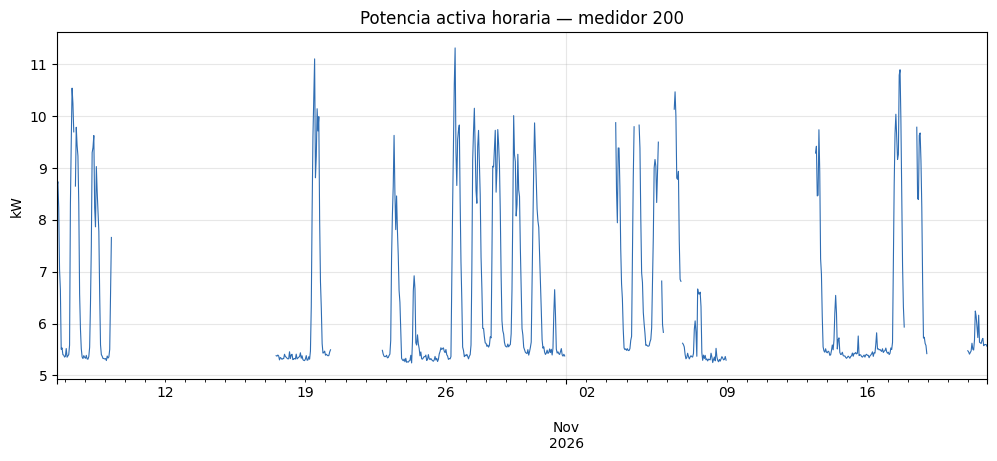

In [2]:
d = pd.read_csv(DATA, parse_dates=["ts_utc"], index_col="ts_utc")
d.index = pd.to_datetime(d.index, utc=True)
P = d["P"].tz_convert("America/Bogota")

h = P.resample("1h").agg(P="mean", n="count")
h.loc[h["n"] < 30, "P"] = np.nan
print(f"Horas: {len(h)} | válidas: {int(h['P'].notna().sum())} | días: {len(set(h.index.date))}")
display(h.describe().round(3).T)

fig, ax = plt.subplots()
h["P"].plot(ax=ax, lw=0.8, color="#2f6db3")
ax.set_title("Potencia activa horaria — medidor 200")
ax.set_ylabel("kW"); ax.set_xlabel("")
fig.savefig(FIG / "01_serie_horaria.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Perfil diario y autocorrelación

El perfil por hora muestra la estacionalidad diaria; la ACF muestra cuánto pesa el día anterior y la semana anterior.

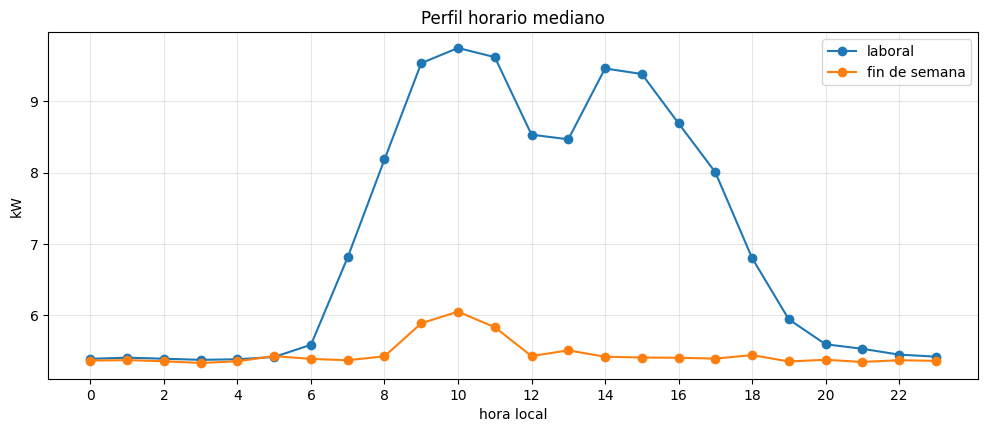

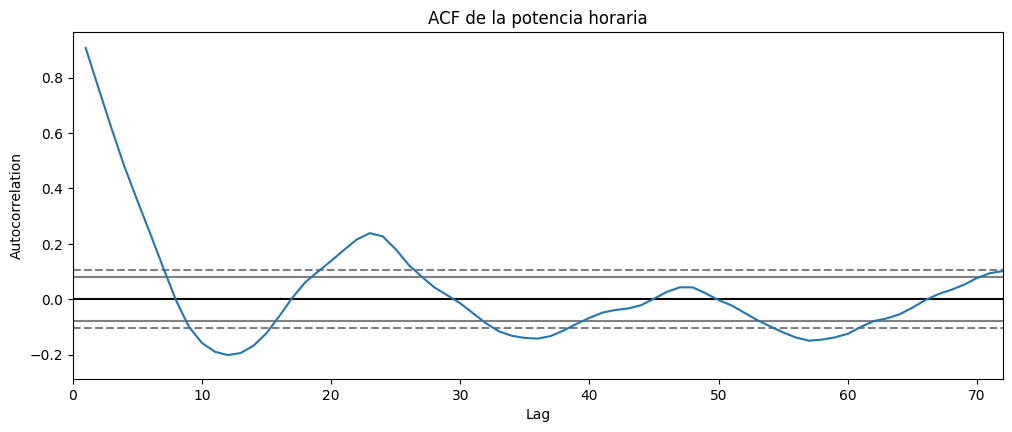

In [3]:
profile = (h.assign(hour=h.index.hour, weekend=h.index.dayofweek >= 5)
             .groupby(["hour", "weekend"])["P"].median().unstack())
profile.columns = ["laboral", "fin de semana"]
fig, ax = plt.subplots()
profile.plot(ax=ax, marker="o")
ax.set_title("Perfil horario mediano")
ax.set_xlabel("hora local"); ax.set_ylabel("kW")
ax.set_xticks(range(0, 24, 2))
fig.savefig(FIG / "01_perfil_diario.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots()
pd.plotting.autocorrelation_plot(h["P"].dropna(), ax=ax)
ax.set_xlim(0, 72)
ax.set_title("ACF de la potencia horaria")
fig.savefig(FIG / "01_acf.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Construcción del dataset multipaso

Para cada origen $t_0$ y horizonte $h$ se arma una fila con:

- **Features del origen:** $P_{t_0}$, rezagos 1/24/168 h, medias móviles 3/6/24 h y desvío de 24 h.
- **Features del objetivo:** hora, día de la semana y fin de semana de $t_0+h$.
- **Estacionalidad conocida:** $P_{t_0+h-24}$ (misma hora del día anterior) y $P_{t_0+h-168}$ (misma hora de la semana anterior).
- **Horizonte** $h$.

La misma hora del día anterior es la base del **seasonal naive**; el modelo debe mejorarla, no repetirla.

In [4]:
H = 24
h["lag1"] = h["P"].shift(1)
h["lag24"] = h["P"].shift(24)
h["lag168"] = h["P"].shift(168)
h["roll3"] = h["P"].rolling(3).mean()
h["roll6"] = h["P"].rolling(6).mean()
h["roll24"] = h["P"].rolling(24).mean()
h["std24"] = h["P"].rolling(24).std()

rows = []
for t in h.index:
    if t + pd.Timedelta(hours=H) > h.index.max():
        break
    p0 = h.loc[t, "P"]
    if np.isnan(p0):
        continue
    lag24 = h.loc[t, "lag24"]; lag24 = p0 if np.isnan(lag24) else lag24
    lag168 = h.loc[t, "lag168"]; lag168 = lag24 if np.isnan(lag168) else lag168
    roll3 = h.loc[t, "roll3"]; roll3 = p0 if np.isnan(roll3) else roll3
    roll6 = h.loc[t, "roll6"]; roll6 = p0 if np.isnan(roll6) else roll6
    roll24 = h.loc[t, "roll24"]; roll24 = p0 if np.isnan(roll24) else roll24
    std24 = h.loc[t, "std24"]; std24 = 0.0 if np.isnan(std24) else std24
    for k in range(1, H + 1):
        tt = t + pd.Timedelta(hours=k)
        y = h.loc[tt, "P"]
        if np.isnan(y):
            continue
        prev_day = h["P"].get(tt - pd.Timedelta(hours=24), np.nan)
        if np.isnan(prev_day):
            continue
        prev_week = h["P"].get(tt - pd.Timedelta(hours=168), np.nan)
        if np.isnan(prev_week):
            prev_week = prev_day
        a1 = 2 * np.pi * tt.hour / 24
        a2 = 2 * a1
        a3 = 3 * a1
        ad = 2 * np.pi * tt.dayofweek / 7
        rows.append({
            "origin": t, "target": tt, "origin_day": t.date(), "horizon": k,
            "y": y, "P_origin": p0, "lag1": h.loc[t, "lag1"] if not np.isnan(h.loc[t, "lag1"]) else p0,
            "lag24": lag24, "lag168": lag168,
            "roll3": roll3, "roll6": roll6, "roll24": roll24, "std24": std24,
            "prev_day": prev_day, "prev_week": prev_week,
            "target_hour": tt.hour, "target_dow": tt.dayofweek,
            "target_weekend": int(tt.dayofweek >= 5),
            "origin_hour": t.hour, "origin_dow": t.dayofweek,
            "hour_sin1": np.sin(a1), "hour_cos1": np.cos(a1),
            "hour_sin2": np.sin(a2), "hour_cos2": np.cos(a2),
            "hour_sin3": np.sin(a3), "hour_cos3": np.cos(a3),
            "dow_sin": np.sin(ad), "dow_cos": np.cos(ad),
        })

df = pd.DataFrame(rows)
print(f"Filas: {len(df):,} | orígenes: {df.origin.nunique():,} | días: {df.origin_day.nunique()}")
display(df.head())
display(df.groupby("horizon")["y"].agg(["count", "mean", "std"]).round(3).T)

Filas: 10,227 | orígenes: 573 | días: 30


,origin,target,origin_day,horizon,y,P_origin,lag1,lag24,lag168,roll3,...,origin_hour,origin_dow,hour_sin1,hour_cos1,hour_sin2,hour_cos2,hour_sin3,hour_cos3,dow_sin,dow_cos
0,2026-10-06 15:00:00-05:00,2026-10-07 15:00:00-05:00,2026-10-06,24,9.432615,8.620453,8.620453,8.620453,8.620453,8.620453,...,15,1,-0.707107,-0.707107,1.000000,1.194340e-15,-7.071068e-01,0.707107,0.974928,-0.222521
1,2026-10-06 16:00:00-05:00,2026-10-07 15:00:00-05:00,2026-10-06,23,9.432615,8.733903,8.620453,8.733903,8.733903,8.733903,...,16,1,-0.707107,-0.707107,1.000000,1.194340e-15,-7.071068e-01,0.707107,0.974928,-0.222521
2,2026-10-06 16:00:00-05:00,2026-10-07 16:00:00-05:00,2026-10-06,24,9.228484,8.733903,8.620453,8.733903,8.733903,8.733903,...,16,1,-0.866025,-0.500000,0.866025,-5.000000e-01,-4.898587e-16,1.000000,0.974928,-0.222521
3,2026-10-06 17:00:00-05:00,2026-10-07 15:00:00-05:00,2026-10-06,22,9.432615,8.241911,8.733903,8.241911,8.241911,8.532089,...,17,1,-0.707107,-0.707107,1.000000,1.194340e-15,-7.071068e-01,0.707107,0.974928,-0.222521
4,2026-10-06 17:00:00-05:00,2026-10-07 16:00:00-05:00,2026-10-06,23,9.228484,8.241911,8.733903,8.241911,8.241911,8.532089,...,17,1,-0.866025,-0.500000,0.866025,-5.000000e-01,-4.898587e-16,1.000000,0.974928,-0.222521


horizon,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
count,435.000,433.000,430.000,428.000,425.000,424.000,423.000,421.000,420.000,420.000,...,421.000,422.000,424.000,425.000,426.000,429.000,431.000,434.000,436.000,443.000
mean,6.377,6.362,6.343,6.326,6.314,6.315,6.320,6.323,6.326,6.325,...,6.373,6.374,6.381,6.383,6.379,6.384,6.386,6.393,6.391,6.408
std,1.545,1.528,1.519,1.505,1.500,1.508,1.514,1.517,1.515,1.512,...,1.558,1.553,1.555,1.558,1.564,1.566,1.565,1.564,1.561,1.566


## 4. Protocolo experimental

**Ventana de pronóstico:** 24 h hacia adelante, resolución horaria. Para cada origen $t_0$ se predicen $P_{t_0+1},\dots,P_{t_0+24}$.

**Orígenes:** cada hora válida de la serie. Las ventanas se **solapan**: un mismo target puede aparecer en hasta 24 orígenes distintos. El ejemplo del 17-11 usa el origen a medianoche solo para visualizar; el modelo se entrena y evalúa con todos los orígenes.

**Particiones:** los días de origen se ordenan cronológicamente y se dividen en 6 bloques. En el fold $k$ se entrena con los bloques $1,\dots,k$ y se evalúa con el bloque $k+1$. No hay shuffle ni filas de test en entrenamiento. El primer bloque es solo entrenamiento; el último es solo test en el loop. La tabla siguiente muestra los porcentajes exactos.

**Baselines:**

- **Persistencia:** $\hat Y_{t_0+h}=P_{t_0}$.
- **Seasonal naive:** $\hat Y_{t_0+h}=P_{t_0+h-24}$.
- **Climatología:** media de $Y$ por hora y tipo de día en entrenamiento.

**Métricas:** MAE, RMSE y skill contra seasonal naive:

$$
\text{Skill}=1-\frac{\text{MAE}_{\text{modelo}}}{\text{MAE}_{\text{naive}}}.
$$

In [5]:
# Tabla exacta de particiones rolling-origin
days = np.array(sorted(set(df["origin_day"])))
blocks = np.array_split(days, 6)
part_rows = []
for k in range(1, 6):
    tr_days = set().union(*blocks[:k])
    te_days = set(blocks[k])
    tr = df[df.origin_day.isin(tr_days)]
    te = df[df.origin_day.isin(te_days)]
    part_rows.append({
        "fold": k,
        "dias_train": len(tr_days), "dias_test": len(te_days),
        "origenes_train": tr.origin.nunique(), "origenes_test": te.origin.nunique(),
        "filas_train": len(tr), "filas_test": len(te),
        "pct_train_fold": 100 * len(tr) / (len(tr) + len(te)),
        "pct_test_fold": 100 * len(te) / (len(tr) + len(te)),
        "test_inicio": min(te_days), "test_fin": max(te_days),
    })
part = pd.DataFrame(part_rows)
display(part.round(2))
part.to_csv(TAB / "01_particiones.csv", index=False)

# Holdout final (usado para importancia de variables)
final_tr_days = set(days[:-5])
final_te_days = set(days[-5:])
final_tr = df[df.origin_day.isin(final_tr_days)]
final_te = df[df.origin_day.isin(final_te_days)]
print(f"Holdout final: train {len(final_tr):,} filas ({100*len(final_tr)/len(df):.1f} %) | "
      f"test {len(final_te):,} filas ({100*len(final_te)/len(df):.1f} %)")
print(f"Días: {len(final_tr_days)} train | {len(final_te_days)} test")

,fold,dias_train,dias_test,origenes_train,origenes_test,filas_train,filas_test,pct_train_fold,pct_test_fold,test_inicio,test_fin
0,1,5,5,75,82,1029,1338,43.47,56.53,2026-10-18,2026-10-23
1,2,10,5,157,120,2367,2880,45.11,54.89,2026-10-24,2026-10-28
2,3,15,5,277,99,5247,1758,74.90,25.10,2026-10-29,2026-11-04
3,4,20,5,376,94,7005,1212,85.25,14.75,2026-11-05,2026-11-13
4,5,25,5,470,103,8217,2010,80.35,19.65,2026-11-14,2026-11-18


Holdout final: train 8,217 filas (80.3 %) | test 2,010 filas (19.7 %)
Días: 25 train | 5 test


In [6]:
features = ["horizon", "P_origin", "lag1", "lag24", "lag168",
            "roll3", "roll6", "roll24", "std24",
            "prev_day", "prev_week", "target_hour", "target_dow",
            "target_weekend", "origin_hour", "origin_dow",
            "hour_sin1", "hour_cos1", "hour_sin2", "hour_cos2",
            "hour_sin3", "hour_cos3", "dow_sin", "dow_cos"]

days = np.array(sorted(set(df["origin_day"])))
blocks = np.array_split(days, 6)

fold_rows = []
pred_parts = []
for k in range(1, 6):
    train_days = set().union(*blocks[:k])
    test_days = set(blocks[k])
    tr = df[df.origin_day.isin(train_days)].copy()
    te = df[df.origin_day.isin(test_days)].copy()
    if len(te) == 0:
        continue

    clim = tr.groupby(["target_hour", "target_weekend"])["y"].mean()
    tr["clim"] = [clim.get((a, b), tr["y"].mean()) for a, b in zip(tr.target_hour, tr.target_weekend)]
    te["clim"] = [clim.get((a, b), tr["y"].mean()) for a, b in zip(te.target_hour, te.target_weekend)]

    ridge = Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))])
    ridge.fit(tr[features], tr["y"])

    cat_features = ["target_hour", "target_dow"]
    num_features = [f for f in features if f not in cat_features]
    ridge_oh = Pipeline([
        ("pre", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
            ("num", StandardScaler(), num_features),
        ])),
        ("m", Ridge(alpha=1.0)),
    ])
    ridge_oh.fit(tr[features], tr["y"])

    gbm = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05,
                                        max_iter=500, l2_regularization=1.0,
                                        min_samples_leaf=15, random_state=0)
    gbm.fit(tr[features], tr["y"])

    te["pred_ridge"] = ridge.predict(te[features])
    te["pred_ridge_oh"] = ridge_oh.predict(te[features])
    te["pred_gbm"] = gbm.predict(te[features])

    # Híbrido: la climatología captura el perfil; el GBM corrige el residuo
    tr["resid"] = tr["y"] - tr["clim"]
    gbm_res = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03,
                                            max_iter=150, l2_regularization=10.0,
                                            min_samples_leaf=30, random_state=0)
    gbm_res.fit(tr[features], tr["resid"])
    te["pred_hyb"] = te["clim"] + gbm_res.predict(te[features])

    pred_parts.append(te)

    for name, pred in [("persistencia", te["P_origin"]),
                       ("seasonal_naive", te["prev_day"]),
                       ("climatologia", te["clim"]),
                       ("ridge", te["pred_ridge"]),
                       ("ridge_onehot", te["pred_ridge_oh"]),
                       ("gbm", te["pred_gbm"]),
                       ("hibrido", te["pred_hyb"])]:
        fold_rows.append({"fold": k, "modelo": name, "n": len(te),
                          "MAE": mean_absolute_error(te["y"], pred),
                          "RMSE": mean_squared_error(te["y"], pred) ** 0.5})

fold = pd.DataFrame(fold_rows)
pred_df = pd.concat(pred_parts, ignore_index=True)
print("Filas de test:", len(pred_df), "| días:", pred_df.origin_day.nunique())
display(fold.pivot(index="fold", columns="modelo", values="MAE").round(3))
display(fold.groupby("modelo")[["MAE", "RMSE"]].median().round(3).to_string())

Filas de test: 9198 | días: 25


modelo,climatologia,gbm,hibrido,persistencia,ridge,ridge_onehot,seasonal_naive
fold,,,,,,,
1,0.404,1.045,0.392,1.469,0.993,0.877,1.072
2,0.298,0.272,0.274,1.434,0.800,0.774,0.699
3,0.280,0.258,0.220,1.370,0.400,0.368,0.643
4,0.284,0.307,0.259,0.688,0.652,0.684,0.927
5,0.632,0.825,0.643,0.704,0.935,0.950,0.834


'                  MAE   RMSE\nmodelo                      \nclimatologia    0.298  0.477\ngbm             0.307  0.474\nhibrido         0.274  0.454\npersistencia    1.370  1.918\nridge           0.800  1.045\nridge_onehot    0.774  1.016\nseasonal_naive  0.834  1.541'

## 5. Resultados

La tabla anterior es por fold. Ahora se calcula el skill contra seasonal naive y el error por horizonte.

**Modelo híbrido.** La climatología captura el perfil diario; el GBM corrige el residuo:

$$
\hat Y^{\text{hyb}}_{t_0+h}
=
\hat Y^{\text{clim}}_{h,d}
+
\hat r_\theta(x_{t_0},h),
\qquad
r=y-\hat Y^{\text{clim}}.
$$

La idea es que el ML no aprenda el perfil desde cero, sino la desviación respecto del perfil típico.

'        modelo  MAE_mediana  RMSE_mediana  skill_mediano_vs_naive\n       hibrido        0.274         0.454                   0.634\n  climatologia        0.298         0.477                   0.574\n           gbm        0.307         0.474                   0.600\n  ridge_onehot        0.774         1.016                   0.182\n         ridge        0.800         1.045                   0.074\nseasonal_naive        0.834         1.541                   0.000\n  persistencia        1.370         1.918                  -0.370'

' horizonte   n  MAE_naive  MAE_clim  MAE_ridge  MAE_ridge_oh  MAE_gbm  MAE_hyb\n         1 394      0.795     0.353      0.762         0.734    0.465    0.330\n         2 392      0.794     0.359      0.758         0.731    0.463    0.332\n         3 390      0.793     0.363      0.755         0.730    0.464    0.336\n         4 388      0.793     0.367      0.753         0.728    0.464    0.342\n         5 385      0.797     0.369      0.749         0.729    0.464    0.343\n         6 384      0.797     0.372      0.745         0.730    0.462    0.346\n         7 383      0.800     0.375      0.746         0.731    0.464    0.350\n         8 381      0.799     0.374      0.744         0.730    0.466    0.351\n         9 380      0.799     0.377      0.746         0.731    0.473    0.353\n        10 380      0.799     0.378      0.746         0.733    0.483    0.356\n        11 379      0.802     0.381      0.751         0.737    0.494    0.359\n        12 379      0.802     0.384    

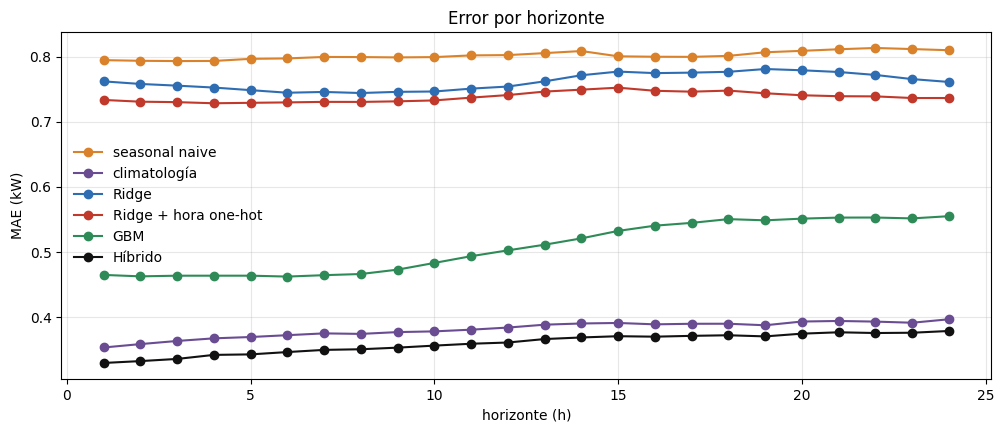

In [7]:
base_mae = fold[fold.modelo == "seasonal_naive"].set_index("fold")["MAE"]
summary = []
for name, g in fold.groupby("modelo"):
    g = g.set_index("fold")
    skill = 1 - g["MAE"] / base_mae.reindex(g.index)
    summary.append({"modelo": name, "MAE_mediana": g["MAE"].median(),
                    "RMSE_mediana": g["RMSE"].median(),
                    "skill_mediano_vs_naive": skill.median()})
summary = pd.DataFrame(summary).sort_values("MAE_mediana")
display(summary.round(3).to_string(index=False))

# MAE por horizonte
hor_rows = []
for hh, g in pred_df.groupby("horizon"):
    hor_rows.append({
        "horizonte": hh, "n": len(g),
        "MAE_naive": mean_absolute_error(g["y"], g["prev_day"]),
        "MAE_clim": mean_absolute_error(g["y"], g["clim"]),
        "MAE_ridge": mean_absolute_error(g["y"], g["pred_ridge"]),
        "MAE_ridge_oh": mean_absolute_error(g["y"], g["pred_ridge_oh"]),
        "MAE_gbm": mean_absolute_error(g["y"], g["pred_gbm"]),
        "MAE_hyb": mean_absolute_error(g["y"], g["pred_hyb"]),
    })
hor = pd.DataFrame(hor_rows)
display(hor.round(3).to_string(index=False))

fig, ax = plt.subplots()
ax.plot(hor.horizonte, hor.MAE_naive, "o-", label="seasonal naive", color="#d9822b")
ax.plot(hor.horizonte, hor.MAE_clim, "o-", label="climatología", color="#6a4c93")
ax.plot(hor.horizonte, hor.MAE_ridge, "o-", label="Ridge", color="#2f6db3")
ax.plot(hor.horizonte, hor.MAE_ridge_oh, "o-", label="Ridge + hora one-hot", color="#c0392b")
ax.plot(hor.horizonte, hor.MAE_gbm, "o-", label="GBM", color="#2e8b57")
ax.plot(hor.horizonte, hor.MAE_hyb, "o-", label="Híbrido", color="#111111")
ax.set_xlabel("horizonte (h)"); ax.set_ylabel("MAE (kW)")
ax.set_title("Error por horizonte")
ax.legend(frameon=False)
fig.savefig(FIG / "01_mae_horizonte.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Ejemplo de pronóstico a 24 h

Se elige un día de test con origen a medianoche y se comparan las 24 horas reales con Ridge, GBM y seasonal naive.

Día elegido: 2026-11-17 | filas: 20


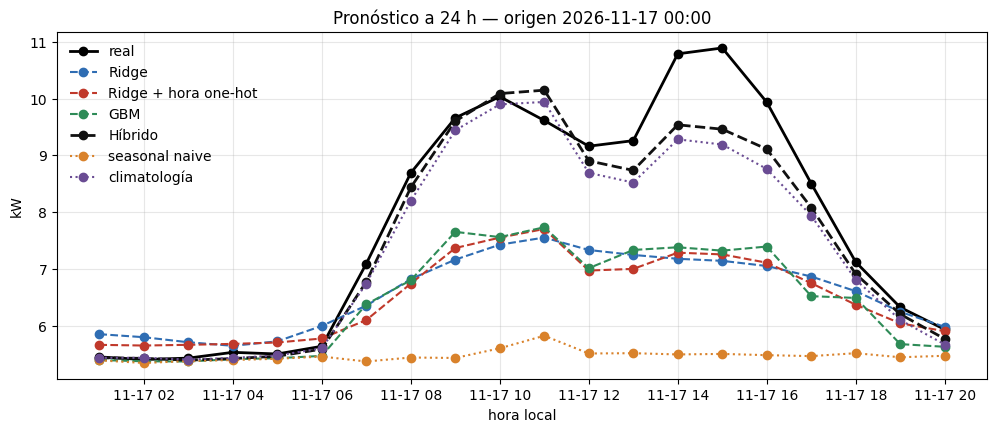

In [8]:
# Día laboral de test con más horas observadas (el último, para que el modelo
# ya haya visto días laborales representativos)
pred_df["origin_weekday"] = pred_df["origin_day"].map(lambda d: pd.Timestamp(d).dayofweek)
cand = (pred_df[(pred_df.origin_hour == 0) & (pred_df.origin_weekday < 5)]
        .groupby("origin_day")["y"].count())
cand = cand[cand >= 20]
day = cand.index[-1]
sel = pred_df[(pred_df.origin_day == day) & (pred_df.origin_hour == 0)].sort_values("target")
print("Día elegido:", day, "| filas:", len(sel))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(sel.target, sel.y, "o-", color="black", label="real", lw=2)
ax.plot(sel.target, sel.pred_ridge, "o--", label="Ridge", color="#2f6db3")
ax.plot(sel.target, sel.pred_ridge_oh, "o--", label="Ridge + hora one-hot", color="#c0392b")
ax.plot(sel.target, sel.pred_gbm, "o--", label="GBM", color="#2e8b57")
ax.plot(sel.target, sel.pred_hyb, "o--", label="Híbrido", color="#111111", lw=2)
ax.plot(sel.target, sel.prev_day, "o:", label="seasonal naive", color="#d9822b")
ax.plot(sel.target, sel.clim, "o:", label="climatología", color="#6a4c93")
ax.set_title(f"Pronóstico a 24 h — origen {day} 00:00")
ax.set_ylabel("kW"); ax.set_xlabel("hora local")
ax.legend(frameon=False)
fig.savefig(FIG / "01_ejemplo_24h.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Modelo final, funcionalidad y generalización

El modelo final es el **híbrido con residuo GBM regularizado**. Se entrena con todos los días menos los últimos 5 y se guarda junto con la climatología para pronosticar días nuevos.

Modelo final — MAE train 0.1500 | MAE test 0.6431 | brecha 0.4931
RMSE test 1.3394


'    feature  importance\n  hour_cos1      0.0169\n target_dow      0.0147\n  prev_week      0.0118\n   prev_day      0.0045\ntarget_hour      0.0030\n origin_dow      0.0030\n  hour_cos3      0.0016\n  hour_sin2      0.0013\n     lag168      0.0004\n  hour_sin3      0.0003\n  hour_cos2      0.0001\n      roll3      0.0000'

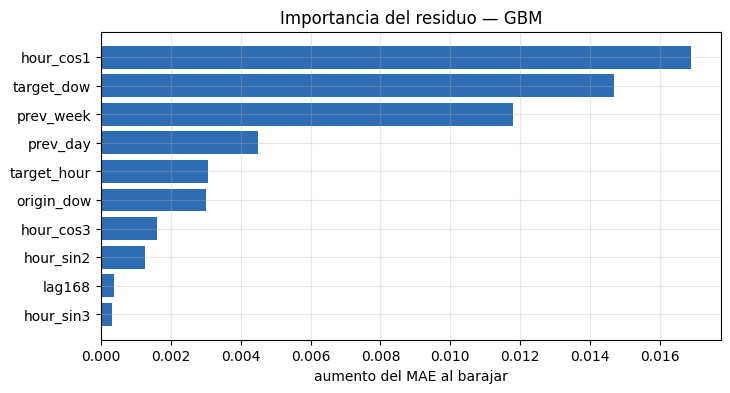

Modelo guardado en Proyecto\potencia_activa\models\pronostico_24h.joblib


In [9]:
# Modelo final: híbrido con residuo regularizado
final_days = set(days[:-5])
final_te_days = set(days[-5:])
final_tr = df[df.origin_day.isin(final_days)].copy()
final_te = df[df.origin_day.isin(final_te_days)].copy()

clim_final = final_tr.groupby(["target_hour", "target_weekend"])["y"].mean()
final_tr["clim"] = [clim_final.get((a, b), final_tr["y"].mean()) for a, b in zip(final_tr.target_hour, final_tr.target_weekend)]
final_te["clim"] = [clim_final.get((a, b), final_tr["y"].mean()) for a, b in zip(final_te.target_hour, final_te.target_weekend)]
final_tr["resid"] = final_tr["y"] - final_tr["clim"]
final_te["resid"] = final_te["y"] - final_te["clim"]

gbm_final = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03,
                                          max_iter=150, l2_regularization=10.0,
                                          min_samples_leaf=30, random_state=0)
gbm_final.fit(final_tr[features], final_tr["resid"])

final_tr["pred"] = final_tr["clim"] + gbm_final.predict(final_tr[features])
final_te["pred"] = final_te["clim"] + gbm_final.predict(final_te[features])
mae_tr = mean_absolute_error(final_tr["y"], final_tr["pred"])
mae_te = mean_absolute_error(final_te["y"], final_te["pred"])
print(f"Modelo final — MAE train {mae_tr:.4f} | MAE test {mae_te:.4f} | brecha {mae_te - mae_tr:.4f}")
print(f"RMSE test {mean_squared_error(final_te['y'], final_te['pred']) ** 0.5:.4f}")

bundle = {"features": features, "clim": clim_final,
          "fallback": float(final_tr["y"].mean()), "gbm_res": gbm_final}
joblib.dump(bundle, MODELS / "pronostico_24h.joblib")

# Importancia del residuo
imp = permutation_importance(gbm_final, final_te[features], final_te["resid"],
                             scoring="neg_mean_absolute_error",
                             n_repeats=3, random_state=0)
imp_df = pd.DataFrame({"feature": features,
                       "importance": imp.importances_mean}).sort_values("importance", ascending=False)
display(imp_df.head(12).round(4).to_string(index=False))
imp_df.to_csv(TAB / "01_importancia.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
top = imp_df.head(10).iloc[::-1]
ax.barh(top.feature, top.importance, color="#2f6db3")
ax.set_xlabel("aumento del MAE al barajar")
ax.set_title("Importancia del residuo — GBM")
fig.savefig(FIG / "01_importancia.png", dpi=150, bbox_inches="tight")
plt.show()

h.to_csv(OUT / "potencia_horaria.csv")
fold.to_csv(TAB / "01_metricas_folds.csv", index=False)
summary.to_csv(TAB / "01_resumen_modelos.csv", index=False)
hor.to_csv(TAB / "01_mae_horizonte.csv", index=False)
print("Modelo guardado en", MODELS / "pronostico_24h.joblib")

### Funcionalidad: pronóstico de un día

`forecast_day(historia, bundle)` recibe la serie horaria hasta el origen y devuelve las próximas 24 h con la curva, la energía diaria, el pico y la hora del pico. El ejemplo usa la historia hasta el 16-11 23:00 para pronosticar el 17-11.

In [10]:
import sys
sys.path.insert(0, str(Path.cwd()))
from forecast import forecast_day, summary_forecast

bundle = joblib.load(MODELS / "pronostico_24h.joblib")
hist = h["P"].loc[:"2026-11-16 23:00"].dropna()
fc = forecast_day(hist, bundle)
display(fc.round(3))
display(pd.DataFrame([summary_forecast(fc)]).round(2))

actual = h["P"].loc["2026-11-17"].dropna()
fc_match = fc.set_index("target").loc[actual.index]
print(f"Real 11-17 ({len(actual)} h): {actual.sum():.1f} kWh | pico {actual.max():.2f} kW")
print(f"Pronóstico en las mismas horas: {fc_match['P_hat'].sum():.1f} kWh | "
      f"MAE {mean_absolute_error(actual, fc_match['P_hat']):.3f} kW")

<tmp>\ipykernel_24976\245820060.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(fc.round(3))


,target,P_hat,P_clim,resid_hat,hora
0,2026-11-17 00:00:00-05:00,5.452,5.442,0.010,00:00
1,2026-11-17 01:00:00-05:00,5.436,5.433,0.003,01:00
2,2026-11-17 02:00:00-05:00,5.425,5.433,-0.008,02:00
3,2026-11-17 03:00:00-05:00,5.394,5.403,-0.009,03:00
4,2026-11-17 04:00:00-05:00,5.421,5.432,-0.011,04:00
5,2026-11-17 05:00:00-05:00,5.463,5.475,-0.011,05:00
6,2026-11-17 06:00:00-05:00,5.594,5.598,-0.004,06:00
7,2026-11-17 07:00:00-05:00,6.778,6.739,0.039,07:00
8,2026-11-17 08:00:00-05:00,8.440,8.197,0.244,08:00
9,2026-11-17 09:00:00-05:00,9.604,9.440,0.164,09:00


,energia_kwh,pico_kw,hora_pico
0,172.74,10.15,2026-11-17 11:00:00-05:00


Real 11-17 (21 h): 161.4 kWh | pico 10.89 kW
Pronóstico en las mismas horas: 156.0 kWh | MAE 0.317 kW


### ¿Memoriza? Cuatro controles

1. **Brecha train/test** del modelo final.
2. **Etiquetas barajadas:** si memoriza, el test no cae al azar.
3. **Curva de aprendizaje:** el test debe mejorar con más días.
4. **Ablación de features:** el modelo debe usar las variables, no una tabla.

Brecha train/test: 0.4931


Etiquetas barajadas: media 1.2737 | rango [1.2588, 1.2861] | media baseline 1.2710


,dias_train,filas_train,MAE_train,MAE_test
0,5,1029,0.020,0.784
1,10,2367,0.045,0.718
2,15,5247,0.110,0.631
3,20,7005,0.129,0.635
4,25,8217,0.150,0.643


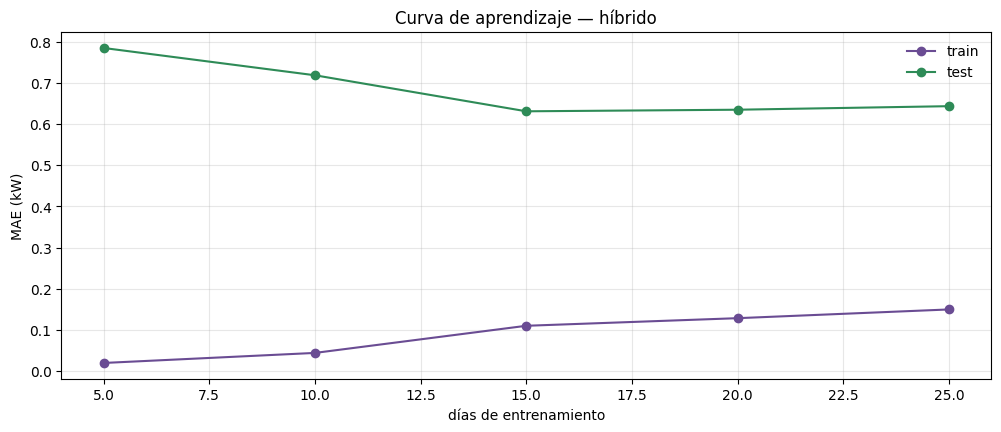

,ablacion,MAE_test
0,completo,0.6431
1,sin prev_day,0.6383
2,sin prev_day/prev_week,0.6521
3,sin lags,0.6439
4,sin calendario,0.6347


Guardado en Proyecto\potencia_activa\reports\tables


In [11]:
# 1. Brecha
print(f"Brecha train/test: {mae_te - mae_tr:.4f}")

# 2. Etiquetas barajadas
base_mean = float(final_tr["y"].mean())
mean_mae = mean_absolute_error(final_te["y"], np.full(len(final_te), base_mean))
shuffle_scores = []
for seed in range(5):
    tr_sh = final_tr.copy()
    tr_sh["y"] = np.random.RandomState(seed).permutation(tr_sh["y"].values)
    clim_sh = tr_sh.groupby(["target_hour", "target_weekend"])["y"].mean()
    tr_sh["clim"] = [clim_sh.get((a, b), tr_sh["y"].mean()) for a, b in zip(tr_sh.target_hour, tr_sh.target_weekend)]
    tr_sh["resid"] = tr_sh["y"] - tr_sh["clim"]
    g = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=150,
                                      l2_regularization=10.0, min_samples_leaf=30,
                                      random_state=seed)
    g.fit(tr_sh[features], tr_sh["resid"])
    te_sh = final_te.copy()
    te_sh["clim"] = [clim_sh.get((a, b), tr_sh["y"].mean()) for a, b in zip(te_sh.target_hour, te_sh.target_weekend)]
    p = te_sh["clim"] + g.predict(te_sh[features])
    shuffle_scores.append(mean_absolute_error(final_te["y"], p))
print(f"Etiquetas barajadas: media {np.mean(shuffle_scores):.4f} | "
      f"rango [{np.min(shuffle_scores):.4f}, {np.max(shuffle_scores):.4f}] | "
      f"media baseline {mean_mae:.4f}")

# 3. Curva de aprendizaje
curve_rows = []
for n in [5, 10, 15, 20, 25]:
    sub = df[df.origin_day.isin(set(days[:n]))].copy()
    clim_n = sub.groupby(["target_hour", "target_weekend"])["y"].mean()
    sub["clim"] = [clim_n.get((a, b), sub["y"].mean()) for a, b in zip(sub.target_hour, sub.target_weekend)]
    te_n = final_te.copy()
    te_n["clim"] = [clim_n.get((a, b), sub["y"].mean()) for a, b in zip(te_n.target_hour, te_n.target_weekend)]
    sub["resid"] = sub["y"] - sub["clim"]
    g = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=150,
                                      l2_regularization=10.0, min_samples_leaf=30,
                                      random_state=0)
    g.fit(sub[features], sub["resid"])
    curve_rows.append({"dias_train": n, "filas_train": len(sub),
                       "MAE_train": mean_absolute_error(sub["y"], sub["clim"] + g.predict(sub[features])),
                       "MAE_test": mean_absolute_error(final_te["y"], te_n["clim"] + g.predict(final_te[features]))})
curve = pd.DataFrame(curve_rows)
display(curve.round(3))

fig, ax = plt.subplots()
ax.plot(curve.dias_train, curve.MAE_train, "o-", label="train", color="#6a4c93")
ax.plot(curve.dias_train, curve.MAE_test, "o-", label="test", color="#2e8b57")
ax.set_xlabel("días de entrenamiento"); ax.set_ylabel("MAE (kW)")
ax.set_title("Curva de aprendizaje — híbrido")
ax.legend(frameon=False)
fig.savefig(FIG / "01_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Ablación
ablations = {
    "completo": features,
    "sin prev_day": [f for f in features if f != "prev_day"],
    "sin prev_day/prev_week": [f for f in features if f not in ("prev_day", "prev_week")],
    "sin lags": [f for f in features if f not in ("lag1", "lag24", "lag168")],
    "sin calendario": [f for f in features if f not in ("target_hour", "target_dow", "target_weekend",
                                                         "hour_sin1", "hour_cos1", "hour_sin2", "hour_cos2",
                                                         "hour_sin3", "hour_cos3", "dow_sin", "dow_cos")],
}
abl_rows = []
for name, feats in ablations.items():
    clim_a = final_tr.groupby(["target_hour", "target_weekend"])["y"].mean()
    tr_a = final_tr.copy(); te_a = final_te.copy()
    tr_a["clim"] = [clim_a.get((a, b), tr_a["y"].mean()) for a, b in zip(tr_a.target_hour, tr_a.target_weekend)]
    te_a["clim"] = [clim_a.get((a, b), tr_a["y"].mean()) for a, b in zip(te_a.target_hour, te_a.target_weekend)]
    tr_a["resid"] = tr_a["y"] - tr_a["clim"]
    g = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.03, max_iter=150,
                                      l2_regularization=10.0, min_samples_leaf=30,
                                      random_state=0)
    g.fit(tr_a[feats], tr_a["resid"])
    abl_rows.append({"ablacion": name, "MAE_test": mean_absolute_error(te_a["y"], te_a["clim"] + g.predict(te_a[feats]))})
abl = pd.DataFrame(abl_rows)
display(abl.round(4))

gen = pd.DataFrame([
    {"prueba": "brecha_train_test", "valor": mae_te - mae_tr},
    {"prueba": "shuffle_MAE_media", "valor": float(np.mean(shuffle_scores))},
    {"prueba": "baseline_media_MAE", "valor": mean_mae},
    {"prueba": "learning_curve_test_final", "valor": float(curve.MAE_test.iloc[-1])},
])
gen.to_csv(TAB / "01_generalizacion.csv", index=False)
abl.to_csv(TAB / "01_ablacion.csv", index=False)
curve.to_csv(TAB / "01_learning_curve.csv", index=False)
print("Guardado en", TAB)

## 8. Conclusiones

- El **modelo final es el híbrido con residuo GBM regularizado**; la climatología es el **baseline**, no el modelo.
- El híbrido mejora ~8 % a la climatología (0,274 vs 0,298) y ~11 % al GBM solo (0,307); RMSE 0,454 y skill 0,634.
- El **último fold es difícil**: test MAE 0,643, train 0,150, brecha 0,493. El mediano 0,274 es el rendimiento típico, no el peor caso.
- **No memoriza ruido:** con etiquetas barajadas el MAE cae a 1,274 (baseline 1,271). La curva de aprendizaje baja de 0,784 a 0,631 al crecer el train. La brecha se reporta.
- **Funcionalidad:** `forecast_day` entrega 24 h, energía diaria y pico. Para el 17-11: 172,7 kWh y pico 10,15 kW a las 11:00; el real fue 161,4 kWh en 21 h; en las mismas horas, 156,0 kWh y MAE 0,317 kW.
- El primer lunes completo (10-19) no se predice bien por cobertura; el 11-16 es un día atípico.
- La cobertura manda: 47 días, 45,3 % de faltantes y ~609 horas válidas. El proyecto es un MVP.
- Próximos pasos: más días continuos, feriados/ocupación y pronóstico probabilístico con cuantiles.
